# Tugas praktikum : multiple linear regression data kafe

In [1]:
# Langkah 1 - Import Library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Langkah 2 - Baca dan pahami data
data = pd.read_csv('../../dataset_pbl/cafes.csv')
data.head()
data.info()
data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 302 entries, 0 to 301
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   cafe_id        302 non-null    str    
 1   name           302 non-null    str    
 2   address        302 non-null    str    
 3   latitude       302 non-null    float64
 4   longitude      302 non-null    float64
 5   rating         302 non-null    float64
 6   review_count   302 non-null    int64  
 7   categories     302 non-null    str    
 8   phone          222 non-null    str    
 9   website        124 non-null    str    
 10  price_range    265 non-null    str    
 11  price_min      265 non-null    float64
 12  price_max      265 non-null    float64
 13  opening_hours  296 non-null    str    
 14  scraped_at     302 non-null    str    
 15  source_query   176 non-null    str    
dtypes: float64(5), int64(1), str(10)
memory usage: 143.0 KB


,latitude,longitude,rating,review_count,price_min,price_max
count,302.000000,302.000000,302.000000,302.000000,265.000000,265.000000
mean,-7.958872,112.629606,4.654636,868.539735,15747.505660,22924.864151
std,0.013686,0.016089,0.241868,1409.505148,14506.693523,23444.357890
min,-7.994386,112.603491,3.200000,1.000000,1.000000,1.000000
25%,-7.969487,112.618566,4.500000,92.000000,1.000000,1.000000
50%,-7.959989,112.625814,4.700000,370.500000,25000.000000,25000.000000
75%,-7.946633,112.639973,4.800000,1056.750000,25000.000000,25000.000000
max,-7.926703,112.672867,5.000000,14193.000000,75000.000000,150000.000000


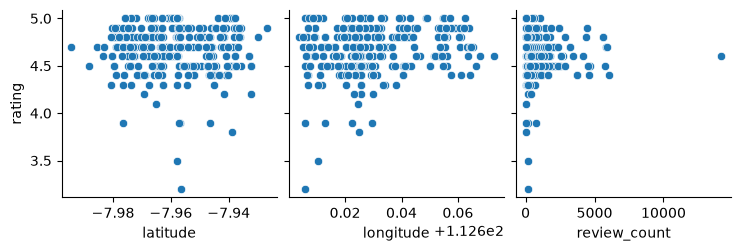

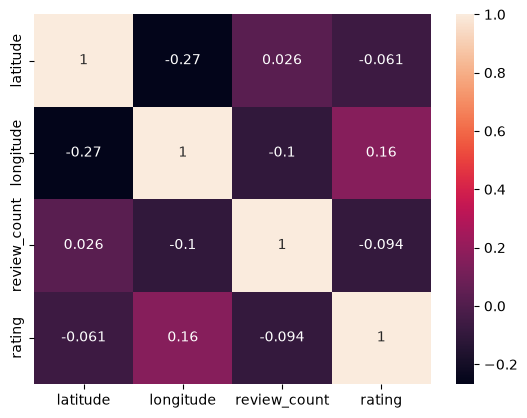

In [3]:
# Langkah 3 - Visualisasi data
sns.pairplot(data, x_vars=['latitude', 'longitude', 'review_count'], y_vars='rating', kind='scatter')
plt.show()
sns.heatmap(data[['latitude', 'longitude', 'review_count', 'rating']].corr(), annot=True)
plt.show()

In [4]:
# Langkah 4 - Fitur, target, dan split 70:30
from sklearn.model_selection import train_test_split
X = data[['latitude', 'longitude', 'review_count']]
y = data['rating']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=100)

In [5]:
# Langkah 5 - Feature scaling
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
# Langkah 6 - Multiple Linear Regression
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(X_train_scaled, y_train)
print('Intercept:', regressor.intercept_)
print(pd.Series(regressor.coef_, index=X.columns))

Intercept: 4.645971563981031
latitude       -0.008930
longitude       0.049807
review_count   -0.018517
dtype: float64


In [7]:
# Langkah 7 - Prediksi data uji
y_pred = regressor.predict(X_test_scaled)
pd.DataFrame({'Rating aktual': y_test, 'Rating prediksi': y_pred}).head(10)

,Rating aktual,Rating prediksi
197,4.7,4.592898
205,4.5,4.612285
112,4.3,4.672540
267,4.5,4.536604
46,4.3,4.646071
159,4.9,4.694710
27,5.0,4.649108
299,4.4,4.752301
161,4.5,4.638366
18,4.8,4.696320


In [8]:
# Langkah 8 - Evaluasi
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
r_squared = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
print('R-squared:', r_squared)
print('MSE:', mse)
print('MAE:', mae)
print('RMSE:', rmse)

R-squared: -0.08143152165691214
MSE: 0.04910255429815228
MAE: 0.17792027497617408
RMSE: 0.22159096167974063


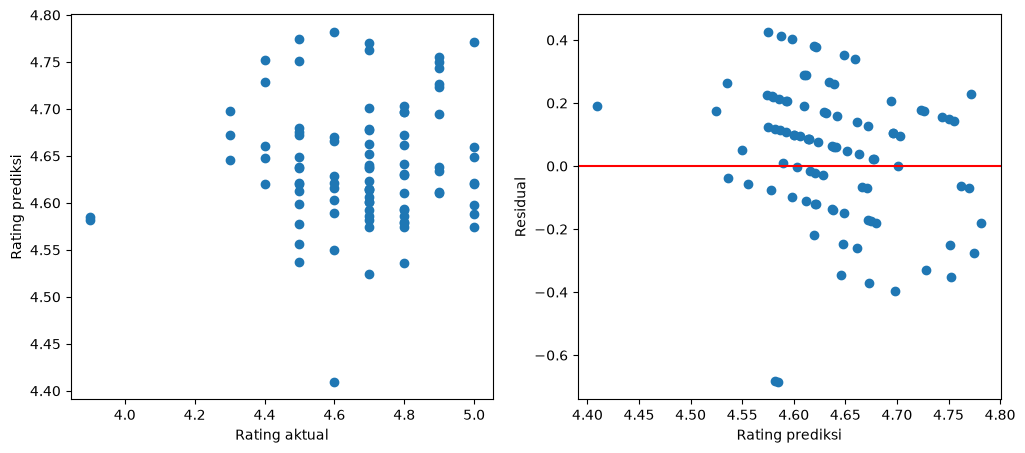

In [9]:
# Langkah 9 - Visualisasi prediksi dan residual
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_test, y_pred)
axes[0].set(xlabel='Rating aktual', ylabel='Rating prediksi')
axes[1].scatter(y_pred, y_test - y_pred)
axes[1].axhline(0, color='red')
axes[1].set(xlabel='Rating prediksi', ylabel='Residual')
plt.show()

## Hasil

R-squared data uji: -0.0814. MAE: 0.1779 dan RMSE: 0.2216 dalam satuan rating